# Projeto 2 — n-gramas, PMI e regressão logística para extrair relações clínicas

**Pergunta.** O Projeto 1 decidia se havia relação entre duas entidades com regras escritas à mão
(um CRF com pesos definidos pela equipe e um léxico de 140 gatilhos). Um modelo estatístico clássico,
sem LLMs nem embeddings, consegue decidir melhor? E o grafo resultante muda?

**Cadeia do projeto** (cada peça alimenta a seguinte):

```
texto entre duas entidades
   │  n-gramas ............ quais sequências de palavras existem
   ▼
PMI / LLR ................... quais bigramas se atraem mais do que o acaso
   ▼
modelo de linguagem ......... quão "relacional" soa o trecho (empilhamento, Wolpert 1992)
   ▼
regressão logística ......... decide: há relação? de que tipo?
   ▼
grafo de conhecimento ....... comparado com o do Projeto 1
```

**Controle.** Os pares candidatos são os do Projeto 1, sem alteração. Os dois sistemas veem exatamente
os mesmos pares; qualquer diferença vem de quem decide.

**Como rodar.** Na pasta `project2`, com `PYTHONPATH=src`. Este caderno usa o pacote `clinical_kg.learning`
e os arquivos já gerados em `data/processed/` (`bash run_all.sh` os regenera).

## 0. Preparação

In [1]:
import collections, csv, os, sys
from pathlib import Path

raiz = Path.cwd()
while not (raiz / "src" / "clinical_kg").exists() and raiz != raiz.parent:
    raiz = raiz.parent
sys.path.insert(0, str(raiz / "src"))
os.chdir(raiz)

import pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 150)
pd.set_option("display.max_colwidth", 80)
print("raiz do projeto:", raiz.name)

raiz do projeto: project2


## 1. O corpus e os pares candidatos (isto não muda)

50 relatos de caso (MultiCaRe/PubMed Central), com as entidades já extraídas do gazetteer UMLS.
Dez desses casos têm **413 pares julgados à mão** (o *gold*): para cada par de entidades próximas,
uma pessoa disse se há relação e de que tipo.

In [2]:
from clinical_kg.learning.pipeline import ler_casos, textos_dos_casos, entidades_lf, textos_entre_candidatos
from clinical_kg.learning.modelo import carregar_exemplos, NENHUMA

casos = ler_casos()
textos = textos_dos_casos()
entidades = entidades_lf()
exemplos = carregar_exemplos()          # os 413 pares do gold, descritos com os candidatos do P1

print(f"{len(casos)} casos · {sum(len(v) for v in entidades.values())} entidades · {len(exemplos)} pares julgados "
      f"em {len({e.caso for e in exemplos})} casos")
pd.Series(collections.Counter(e.relacao for e in exemplos), name="pares").sort_values(ascending=False).to_frame()

50 casos · 2957 entidades · 413 pares julgados em 10 casos


,pares
NENHUMA,192
COORDINATE_WITH,80
LOCATED_IN,42
TREATED_WITH,32
HAS_DIAGNOSIS,21
REVEALED_BY,20
HAS_FINDING,13
HAS_SYMPTOM,9
CAUSED_BY,4


In [3]:
e = next(x for x in exemplos if x.relacao == "TREATED_WITH")
print(f"cabeça : {e.cabeca}\ncauda  : {e.cauda}\nentre  : {' '.join(e.entre)!r}\ngold   : {e.relacao}")

cabeça : PATIENT
cauda  : supportive care
entre  : 'he was started on antibiotics and'
gold   : TREATED_WITH


`CAUSED_BY` tem **4 exemplos**: pouco demais para aprender uma classe. Voltaremos a isso na seção 8.

## 2. N-gramas

Um n-grama é uma sequência de *n* palavras seguidas. É o material com que o projeto trabalha:
o texto **entre** duas entidades ("was treated with") carrega, em geral, a relação.

In [4]:
from clinical_kg.learning.ngramas import tokenizar, contar_ngramas

frase = "The patient was treated with aspirin and discharged."
tokens = tokenizar(frase)
print(tokens)
for n in (2, 3):
    print(f"{n}-gramas:", [" ".join(g) for g in contar_ngramas(tokens, n) if len(g) == n])

['the', 'patient', 'was', 'treated', 'with', 'aspirin', 'and', 'discharged']
2-gramas: ['the patient', 'patient was', 'was treated', 'treated with', 'with aspirin', 'aspirin and', 'and discharged']
3-gramas: ['the patient was', 'patient was treated', 'was treated with', 'treated with aspirin', 'with aspirin and', 'aspirin and discharged']


In [5]:
bigramas = collections.Counter()
for t in textos.values():
    tokens = tokenizar(t)
    bigramas.update(zip(tokens, tokens[1:]))
unicos = sum(1 for c in bigramas.values() if c == 1)
print(f"{len(bigramas):,} bigramas distintos; {unicos / len(bigramas):.1%} aparecem uma única vez")

16,961 bigramas distintos; 81.7% aparecem uma única vez


Esse último número explica as escolhas seguintes: com um corpus tão pequeno, a maioria dos bigramas
é vista uma só vez, então estatísticas ingênuas enganam. Por isso o PMI exige contagem mínima e o
modelo de linguagem usa suavização.

## 3. PMI e LLR: quais bigramas se atraem?

**PMI** (Church & Hanks, 1990) compara a frequência de um par com a que o acaso daria:

$$\mathrm{PMI}(a,b) = \log_2 \frac{P(a,b)}{P(a)\,P(b)}$$

Alto significa que as palavras formam uma unidade; perto de zero, que são independentes.
O **LLR** (Dunning, 1993) mede a mesma associação com um teste que não supõe contagens esperadas grandes,
justamente o regime de um corpus pequeno. Para não premiar pares vistos uma vez, o PMI vale zero
abaixo de 5 ocorrências.

In [6]:
from clinical_kg.learning.ngramas import Associacoes

assoc = Associacoes(textos.values())
topo = pd.DataFrame([(f"{a} {b}", c, round(pmi, 2), round(assoc.llr(a, b), 1))
                     for a, b, c, pmi in assoc.ranking("pmi")[:12]],
                    columns=["bigrama", "contagem", "PMI", "LLR"])
topo

,bigrama,contagem,PMI,LLR
0,magnetic resonance,6,12.05,112.2
1,united states,6,12.05,112.2
2,erythrocyte sedimentation,5,11.79,84.5
3,vp shunt,5,11.63,84.7
4,one-lung ventilation,5,11.31,81.4
5,cecal appendix,5,11.17,80.1
6,pleural effusion,7,11.10,109.6
7,human herpesvirus,5,11.05,79.0
8,sinus rhythm,7,10.95,107.0
9,intensive care,6,10.93,94.2


O topo do PMI no corpus inteiro são **termos clínicos** ("pleural effusion", "magnetic resonance"),
não gatilhos de relação: os gatilhos ("was treated with") são palavras frequentes e têm PMI baixo.
Por isso, para estudar gatilhos, olhamos só o texto **entre duas entidades**.

In [7]:
from clinical_kg.learning.pipeline import tabela_gatilhos
from clinical_kg.relations.core import features as regras_p1

entre = textos_entre_candidatos([{"case_id": c, "case_text": t} for c, t in textos.items()], entidades)
gatilhos, vistos = tabela_gatilhos(entre)
print(f"{len(entre)} trechos entre entidades")
print(f"léxico escrito à mão no P1: {len(regras_p1.TRIGGER_LEXICON)} palavras; o corpus confirma "
      f"{len(vistos)} delas (≥ 3 vezes entre entidades)")
pd.DataFrame(gatilhos[:15]).rename(columns={"no_lexico_p1": "no léxico P1"})

2391 trechos entre entidades
léxico escrito à mão no P1: 140 palavras; o corpus confirma 53 delas (≥ 3 vezes entre entidades)


,ngrama,contagem_entre,pmi,llr,no léxico P1,categoria_p1
0,patient was,67,3.76,269.7,0,
1,to the,64,1.95,81.7,0,
2,with a,41,2.52,89.8,0,
3,was performed,28,4.56,136.0,1,TREAT
4,due to,27,5.68,200.8,1,CAUSE
5,showed a,26,3.42,76.4,1,REVEAL
6,from the,22,2.90,57.7,0,
7,consistent with,19,5.50,141.3,1,DIAGNOSE
8,did not,19,8.55,213.4,0,
9,patient underwent,18,5.34,97.8,1,TREAT


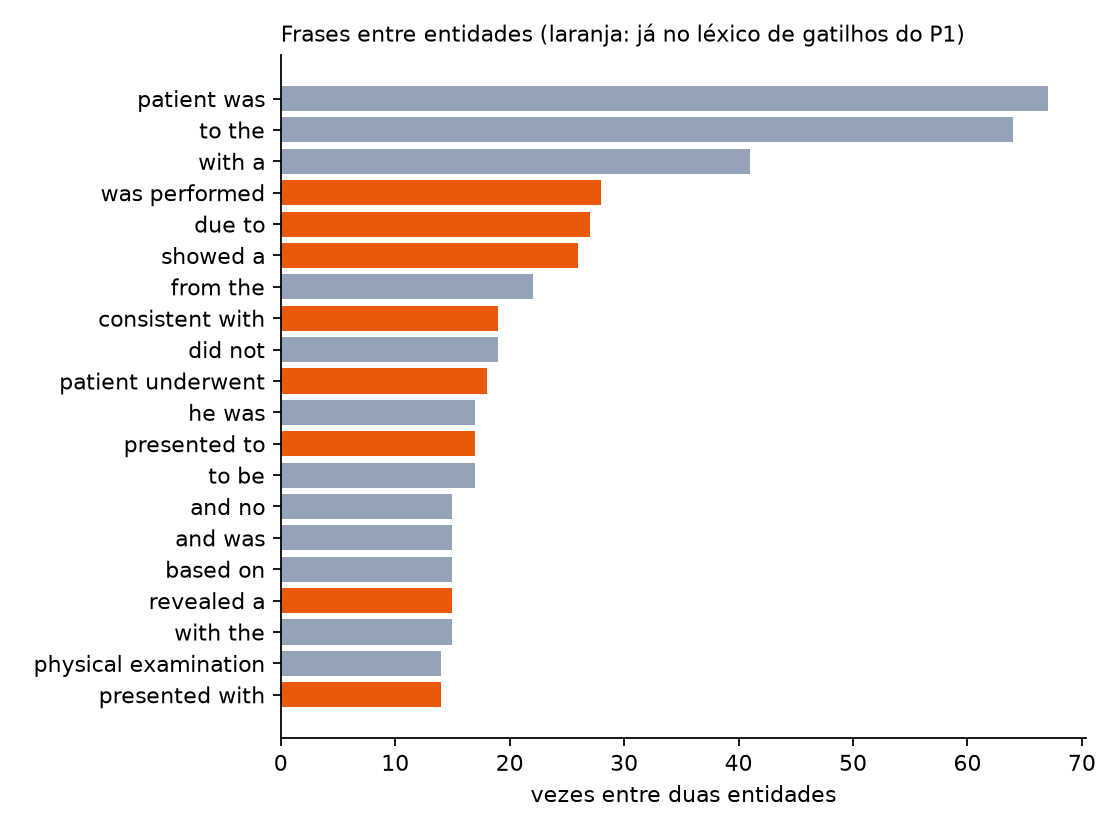

In [8]:
display(Image(filename=str(raiz / "assets/images/frases_entre_entidades.png"), width=560))

Laranja: frases com uma palavra que o P1 já tinha como gatilho. Cinza: o resto (parte é gramática
— "to the", "patient was" —, parte são sinais que as regras não previam, como "based on").

## 4. Modelo de linguagem e empilhamento (stacking)

Colocar milhares de n-gramas como atributos soltos exigiria aprender milhares de pesos com 413 exemplos.
A alternativa é **comprimi-los em um número**: treinam-se dois modelos de linguagem bigrama sobre o texto
entre as entidades, um com os pares **com** relação e outro com os **sem**. A diferença das suas
log-probabilidades (positiva quando o trecho se parece mais com os pares com relação) é o `lm_score`.

In [9]:
from clinical_kg.learning.modelo import PontuadorLM

pontuador = PontuadorLM().ajustar(exemplos)
for trecho in ["was treated with", "revealed", "and", "of the", "xyzzy frobnicate"]:
    print(f"{trecho!r:<22} lm_score = {pontuador.pontuar(tokenizar(trecho)):+.2f}")

'was treated with'     lm_score = -0.05
'revealed'             lm_score = +0.22
'and'                  lm_score = +0.27
'of the'               lm_score = +0.11
'xyzzy frobnicate'     lm_score = +0.04


O que o score aprendeu é modesto e vale ler com cuidado: com 413 exemplos ele capta sobretudo a
**coordenação** ("and") e verbos como "revealed", e quase nada de gatilhos raros no gold como
"was treated with" (negativo ou perto de zero). Não é um detector geral de relações.

**Empilhamento (Wolpert, 1992).** Esse `lm_score` é um atributo de um segundo modelo (a regressão).
Se a regressão treinasse com scores calculados por modelos de linguagem que **já leram o próprio exemplo
e seu rótulo**, veria um sinal bom demais e aprenderia a confiar nele. A regra é: cada exemplo é pontuado
por modelos treinados **sem o seu caso** (validação cruzada por caso).

In [10]:
from clinical_kg.learning.modelo import pontuacoes_fora_de_amostra

fora = pontuacoes_fora_de_amostra(exemplos)
dentro = {e.chave: pontuador.pontuar(e.entre) for e in exemplos}

def media(valores, classe):
    sel = [valores[e.chave] for e in exemplos if bool(e.eh_relacao) == classe]
    return sum(sel) / len(sel)

pd.DataFrame({"dentro da amostra (vaza)": [media(dentro, True), media(dentro, False)],
              "fora de amostra (honesto)": [media(fora, True), media(fora, False)]},
             index=["pares COM relação", "pares SEM relação"]).round(3)

,dentro da amostra (vaza),fora de amostra (honesto)
pares COM relação,0.261,0.083
pares SEM relação,-0.149,0.030


Dentro da amostra o score separa bem as duas classes (0,26 contra −0,15), mas **fora de amostra a separação
quase desaparece** (0,08 contra 0,03). O empilhamento mostra o valor real do atributo, que é pequeno, em vez
do valor inflado que o modelo veria se treinasse com scores calculados sobre o próprio exemplo.

## 5. Regressão logística: decidir e explicar

A decisão é uma regressão logística, **escrita à mão** (SGD com penalidade L2 e peso para classes raras),
uma por relação (um-contra-todos). Os atributos do par: tipos das entidades, distância, pontuação, PMI/LLR
dos bigramas entre elas e o `lm_score`. Ela é interpretável: cada peso diz quanto um atributo empurra
para a relação.

In [11]:
from clinical_kg.learning.modelo import ModeloAprendido

final = ModeloAprendido().ajustar(exemplos, list(textos.values()))
for relacao in ["TREATED_WITH", "HAS_DIAGNOSIS", "COORDINATE_WITH"]:
    print(relacao)
    for nome, w in final.classificador.modelos[relacao].pesos_principais(6):
        print(f"   {w:+7.2f}  {nome}")

TREATED_WITH
     +8.57  par:Treatment>Diagnosis
     -8.57  par:Treatment>Treatment
     +7.10  par:Paciente>Exam
     -6.85  tipo_cauda:BodyPart
     -5.41  distancia:0
     +5.16  par:Symptom>Treatment
HAS_DIAGNOSIS
    +10.03  par:Paciente>Diagnosis
     +6.10  tipo_cauda:Diagnosis
     -5.38  mesma_clausula
     -4.64  distancia:1_3
     -4.62  tipo_cauda:Finding
     -4.61  distancia:0
COORDINATE_WITH
     -6.03  mesma_clausula
     +4.67  par:BodyPart>BodyPart
     +4.09  par:Treatment>Treatment
     +3.66  par:Diagnosis>Diagnosis
     -3.25  llr_max
     +3.06  pmi_max


In [12]:
# O que os atributos vindos dos n-gramas pesam em cada relação
linhas = []
for rel, m in final.classificador.modelos.items():
    linhas.append({"relação": rel, **{a: round(m.pesos.get(a, 0.0), 2) for a in ("lm_score", "pmi_max", "pmi_medio", "llr_max")}})
pd.DataFrame(linhas).set_index("relação")

,lm_score,pmi_max,pmi_medio,llr_max
relação,,,,
CAUSED_BY,-0.06,0.81,-1.27,-1.70
COORDINATE_WITH,2.26,3.06,1.48,-3.25
HAS_DIAGNOSIS,-1.19,4.49,1.53,-1.19
HAS_FINDING,-0.04,0.14,1.52,-0.46
HAS_SYMPTOM,-0.19,0.33,-0.34,-1.78
LOCATED_IN,0.56,-1.42,-0.37,-0.02
NENHUMA,-4.78,-2.78,-0.28,0.43
REVEALED_BY,2.62,-3.49,-1.58,-0.58
TREATED_WITH,0.95,3.65,0.69,1.55


## 6. Comparação com o Projeto 1 (experimental)

**Protocolo.** Deixa-se um caso de fora (*leave-one-case-out*): em cada rodada, o modelo, as contagens de
PMI e os modelos de linguagem são refeitos **sem o caso de teste**. Nenhum número é medido sobre texto que
o modelo já leu. A linha de base é o P1 como foi entregue (dispara se `score ≥ 1.0`).

O P2 aparece em variantes que ligam e desligam peças, incluindo o uso **direto** dos n-gramas (`lexico`: cada frase
de 1 a 3 palavras entre as entidades vira um atributo), mais uma regressão do scikit-learn como verificação
independente.

In [13]:
from clinical_kg.learning.pipeline import prever_validando, medir, confronto, media_dp, DESCRICAO

nomes = ["p1", "estrutura", "lexico", "pmi", "lm", "completo", "completo_sklearn"]
resultados = {n: medir(prever_validando(exemplos, textos, n)) for n in nomes}

linhas = []
for n, m in resultados.items():
    media_f1, dp = media_dp(list(m["por_caso"].values()))
    v, e, d = confronto(m["por_caso"], resultados["p1"]["por_caso"])
    linhas.append({"variante": n, "descrição": DESCRICAO[n], "precisão": m["p"], "cobertura": m["r"],
                   "F1": m["f1"], "tipo certo": m["tipo"], "F1/caso": f"{media_f1:.3f} ± {dp:.3f}",
                   "casos vs P1 (V-E-D)": "—" if n == "p1" else f"{v}-{e}-{d}"})
pd.DataFrame(linhas).set_index("variante").round(3)

,descrição,precisão,cobertura,F1,tipo certo,F1/caso,casos vs P1 (V-E-D)
variante,,,,,,,
p1,Projeto 1 (regras à mão),0.602,0.656,0.628,0.772,0.610 ± 0.142,—
estrutura,"só tipos, distância e pontuação",0.673,0.846,0.749,0.893,0.725 ± 0.075,9-0-1
lexico,estrutura + frases (1 a 3 palavras) como atributos diretos,0.712,0.729,0.720,0.919,0.671 ± 0.166,7-0-3
pmi,estrutura + PMI/LLR,0.674,0.833,0.745,0.908,0.728 ± 0.067,9-0-1
lm,estrutura + modelo de linguagem (stacking),0.687,0.855,0.762,0.889,0.735 ± 0.081,9-0-1
completo,estrutura + PMI/LLR + modelo de linguagem,0.687,0.833,0.753,0.913,0.735 ± 0.053,9-0-1
completo_sklearn,"completo, com a regressão do scikit-learn",0.664,0.851,0.746,0.904,0.730 ± 0.063,9-0-1


**Leitura honesta.**

* O modelo aprendido supera as regras: F1 de ~0,63 para ~0,75 e acerto do tipo de ~0,77 para ~0,9,
  ganhando em 9 dos 10 casos.
* As variantes com PMI e modelo de linguagem ficam entre 0,745 e 0,762, **dentro do ruído** (desvio entre casos de
  0,05 a 0,08). Com 10 casos não se pode afirmar que elas melhorem o F1: contra a variante só de estrutura, o
  modelo completo ganha em 5 casos, empata em 1 e perde em 4.
* **O uso direto dos n-gramas (`lexico`) não ajudou**: o F1 fica em ~0,72 (a diferença para a de estrutura inclui o
  zero no bootstrap) e o desvio entre casos sobe (0,17).
  Ele sobe a precisão (0,71) e o acerto do tipo (0,92) porque o modelo passa a disparar menos (cobertura 0,73), e
  perde para a variante só de estrutura em 7 dos 10 casos. Nem `REVEALED_BY`, a relação mais dependente de uma
  palavra-gatilho, melhora de forma relevante (0,33 → 0,35), e `TREATED_WITH` piora (0,58 → 0,47).
* A regressão à mão e a do scikit-learn dão resultados próximos: a implementação está correta.

**Intervalos de confiança (bootstrap pareado por caso).** Com 10 casos, "ganha em 9 de 10" precisa de um
intervalo. Sorteiam-se casos com reposição (o mesmo sorteio para os dois métodos), calcula-se a diferença de F1
e repete-se 10.000 vezes; o intervalo de 95% são os percentis 2,5 e 97,5. Se ele fica todo acima de zero, a
vantagem é consistente entre casos; se inclui o zero, não se distingue do acaso.

In [14]:
from clinical_kg.learning.pipeline import bootstrap_pareado

contrastes = [("completo", "p1"), ("estrutura", "p1"), ("lexico", "p1"),
              ("completo", "estrutura"), ("pmi", "estrutura"), ("lm", "estrutura"), ("lexico", "estrutura")]
linhas = []
for a, b in contrastes:
    r = bootstrap_pareado(resultados[a]["contagem_por_caso"], resultados[b]["contagem_por_caso"])
    linhas.append({"A − B": f"{a} − {b}", "diferença de F1": r["diferenca"], "IC95 inf": r["ic_inf"],
                   "IC95 sup": r["ic_sup"], "distinguível de zero?": "sim" if r["ic_inf"] > 0 or r["ic_sup"] < 0 else "não"})
pd.DataFrame(linhas).set_index("A − B").round(3)

,diferença de F1,IC95 inf,IC95 sup,distinguível de zero?
A − B,,,,
completo − p1,0.126,0.084,0.180,sim
estrutura − p1,0.123,0.083,0.175,sim
lexico − p1,0.093,0.012,0.178,sim
completo − estrutura,0.003,-0.019,0.026,não
pmi − estrutura,-0.004,-0.023,0.017,não
lm − estrutura,0.012,-0.003,0.029,não
lexico − estrutura,-0.030,-0.090,0.026,não


O P2 supera o P1 de forma consistente (intervalo inteiro acima de zero). Já as diferenças **entre variantes do
P2** incluem o zero: com estes dados, PMI, modelo de linguagem e n-gramas diretos não se distinguem da variante
só de estrutura.

## 6b. Supervisão fraca: o que acontece com os n-gramas quando há mais dados?

Até aqui o modelo aprende com **413 julgamentos humanos**. A *Possibilidade 4* da guia propõe treinar sem
nenhum: as regras do P1 rotulam os **2.391 candidatos dos 50 casos** e o mesmo modelo aprende com esses
rótulos. A prova continua sendo o gold: em cada rodada, o caso do gold retirado fica de fora e o modelo só
viu as etiquetas **das regras** dos outros 49. Isso dá aos n-gramas ~6 vezes mais dados.

Rodar essa validação leva ~4 minutos, então o caderno **lê** o resultado calculado por `pipeline treinar`
(os arquivos `metricas_validacao.csv`, `metricas_bootstrap.csv` e `metricas_fraco.csv`).

In [15]:
mv = pd.read_csv("data/processed/metricas_validacao.csv").set_index("variante")
fracas = [v for v in mv.index if v.startswith("fraco_")]
tabela_fraca = mv.loc[["p1", "completo", *fracas], ["descricao", "precisao", "cobertura", "f1", "tipo_acertado", "f1_caso_media", "f1_caso_dp"]]
tabela_fraca.round(3)

,descricao,precisao,cobertura,f1,tipo_acertado,f1_caso_media,f1_caso_dp
variante,,,,,,,
p1,Projeto 1 (regras à mão),0.602,0.656,0.628,0.772,0.610,0.142
completo,estrutura + PMI/LLR + modelo de linguagem,0.687,0.833,0.753,0.913,0.735,0.054
fraco_estrutura,treinado com as etiquetas do P1 (50 casos): só estrutura,0.587,0.778,0.669,0.762,0.652,0.070
fraco_lexico,treinado com as etiquetas do P1 (50 casos): estrutura + frases diretas,0.621,0.674,0.646,0.785,0.647,0.085
fraco_completo,treinado com as etiquetas do P1 (50 casos): completo (PMI + modelo de lingua...,0.594,0.783,0.676,0.786,0.656,0.080


In [16]:
fraco = pd.read_csv("data/processed/metricas_fraco.csv").set_index("variante")
fraco.columns = ["concorda com o P1", "relações recuperadas", "relações perdidas", "FP removidos", "FP novos"]
fraco.round(3)

,concorda com o P1,relações recuperadas,relações perdidas,FP removidos,FP novos
variante,,,,,
fraco_estrutura,0.772,35,8,13,38
fraco_lexico,0.857,15,11,19,14
fraco_completo,0.806,35,7,8,30


In [17]:
bt = pd.read_csv("data/processed/metricas_bootstrap.csv")
bt = bt[bt.a.str.startswith("fraco_")].copy()
bt["distinguível de zero?"] = ((bt.ic95_inf > 0) | (bt.ic95_sup < 0)).map({True: "sim", False: "não"})
bt.rename(columns={"a": "A", "b": "B", "diferenca_f1": "A − B (F1)"}).set_index(["A", "B"]).round(3)

A − B (F1)  ic95_inf  ic95_sup  prob_a_maior distinguível de zero?
A               B                                                                                  
fraco_completo  p1                    0.049     0.005     0.099         0.987                   sim
fraco_estrutura p1                    0.042     0.016     0.076         0.999                   sim
fraco_lexico    p1                    0.020    -0.012     0.067         0.856                   não
                fraco_estrutura      -0.022    -0.042     0.005         0.051                   não
fraco_completo  fraco_estrutura       0.006    -0.021     0.034         0.669                   não
                completo             -0.078    -0.118    -0.035         0.000                   sim

**Leitura.**

* Com as etiquetas das regras, o modelo só de estrutura fica acima do P1 (diferença que o bootstrap distingue de
  zero) e **recupera relações que as regras perderam**, ao custo de novos falsos positivos.
* Os **n-gramas diretos reproduzem as regras**: F1 perto do P1 (0,646 contra 0,628, diferença que o bootstrap não
  distingue de zero) e a maior concordância com ele (0,857). As frases aprendem o léxico de gatilhos que as regras
  já usavam e também memorizam os erros delas; ficam abaixo da variante só de estrutura, mas o intervalo inclui
  o zero.
* Treinar com os 413 julgamentos humanos supera treinar com as 2.391 etiquetas das regras.

Resposta honesta à pergunta central: com mais dados, os n-gramas capturam bem o que as regras já sabiam, mas
etiquetas que vêm das próprias regras não ensinam nada além delas.

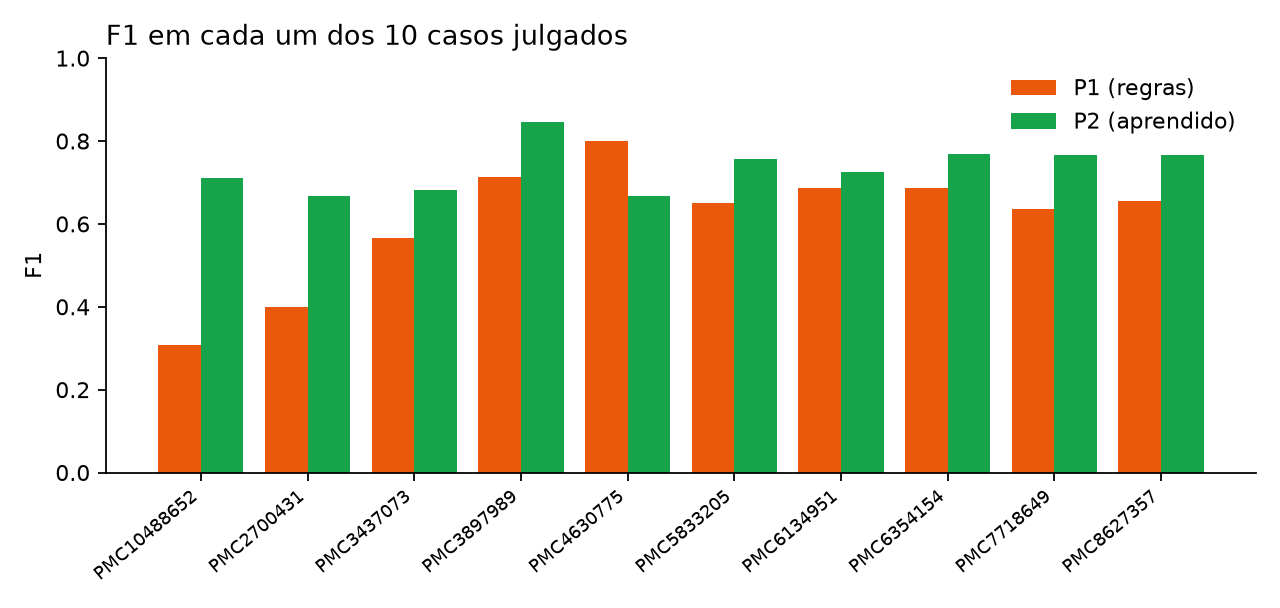

In [18]:
display(Image(filename=str(raiz / "assets/images/f1_por_caso.png"), width=620))

In [19]:
from clinical_kg.learning.pipeline import prf

rel = []
for r in sorted(resultados["completo"]["por_relacao"]):
    a, b = prf(*resultados["p1"]["por_relacao"][r]), prf(*resultados["completo"]["por_relacao"][r])
    rel.append({"relação": r, "F1 P1": a[2], "F1 P2": b[2], "diferença": b[2] - a[2]})
pd.DataFrame(rel).set_index("relação").round(3)

,F1 P1,F1 P2,diferença
relação,,,
CAUSED_BY,0.182,0.000,-0.182
COORDINATE_WITH,0.516,0.751,0.235
HAS_DIAGNOSIS,0.492,0.864,0.372
HAS_FINDING,0.324,0.667,0.342
HAS_SYMPTOM,0.727,0.947,0.220
LOCATED_IN,0.614,0.703,0.090
REVEALED_BY,0.311,0.400,0.089
TREATED_WITH,0.432,0.609,0.176


### Matriz de confusão dos tipos de relação

Cada linha é o tipo julgado à mão (gold) e cada coluna o que o sistema previu; `NENHUMA` é "sem relação".
A diagonal são os acertos. Fora dela há dois erros diferentes: **trocar o tipo** (a relação existe, mas o tipo
sai errado) e **perder a relação** (coluna `NENHUMA`). São as mesmas previsões fora de amostra da comparação
acima (`metricas_matriz_confusao.csv`).

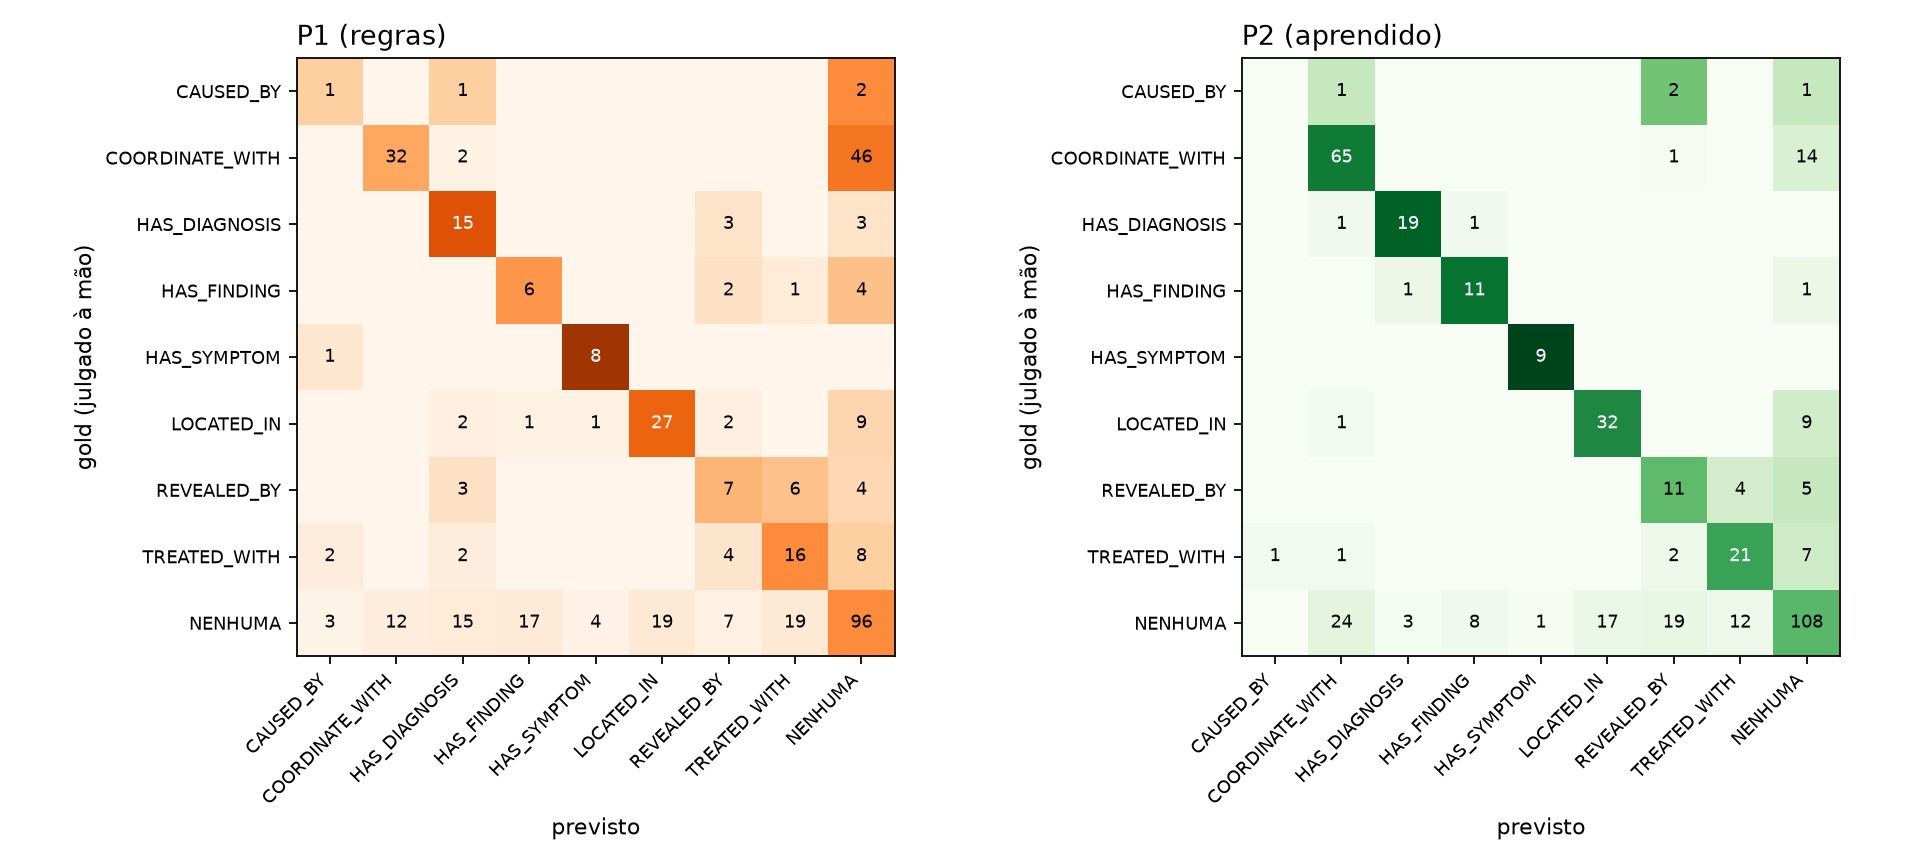

,sistema,relacao,no_gold,tipo_certo,tipo_trocado,perdida
0,p1,CAUSED_BY,4,1,1,2
1,p1,COORDINATE_WITH,80,32,2,46
2,p1,HAS_DIAGNOSIS,21,15,3,3
3,p1,HAS_FINDING,13,6,3,4
4,p1,HAS_SYMPTOM,9,8,1,0
5,p1,LOCATED_IN,42,27,6,9
6,p1,REVEALED_BY,20,7,9,4
7,p1,TREATED_WITH,32,16,8,8
8,completo,CAUSED_BY,4,0,3,1
9,completo,COORDINATE_WITH,80,65,1,14


In [20]:
display(Image(filename=str(raiz / "assets/images/matriz_confusao.png"), width=900))

linhas = []
for nome in ("p1", "completo"):
    m = resultados[nome]["matriz"]
    for t in sorted({r for r, _ in m} - {"NENHUMA"}):
        total = sum(n for (r, _), n in m.items() if r == t)
        linhas.append({"sistema": nome, "relacao": t, "no_gold": total, "tipo_certo": m[(t, t)],
                       "tipo_trocado": sum(n for (r, p), n in m.items() if r == t and p not in (t, "NENHUMA")),
                       "perdida": m[(t, "NENHUMA")]})
pd.DataFrame(linhas)

## 7. Comparação do grafo (qualitativa e estrutural)

Aplicando o modelo final aos 50 casos (`pipeline extrair`), comparam-se os dois grafos. A guia do professor
alerta: desempenho parecido pode esconder grafos muito diferentes.

In [21]:
pd.read_csv("data/processed/comparacao_metricas.csv").fillna("").set_index("metrica")

,p1,p2,nota
metrica,,,
relações extraídas (50 casos),1352,1463.0,"pares únicos (cabeça, cauda, tipo)"
relações por caso,27.0,29.3,
relações idênticas (mesmo par e tipo),628,628.0,Jaccard 0.287
arestas do grafo (conceitos agregados),1299,1399.0,arestas clínicas únicas por caso
arestas idênticas no grafo,609,609.0,Jaccard 0.292
grau médio dos nós conectados,1.68,1.72,2 x arestas / nós com alguma relação clínica
tipos de relação presentes,8,8.0,de 8
F1 no gold (deixa-um-caso-fora),0.6277,0.7526,"413 pares julgados à mão, 10 casos"
tipo acertado no gold,0.7724,0.913,"413 pares julgados à mão, 10 casos"


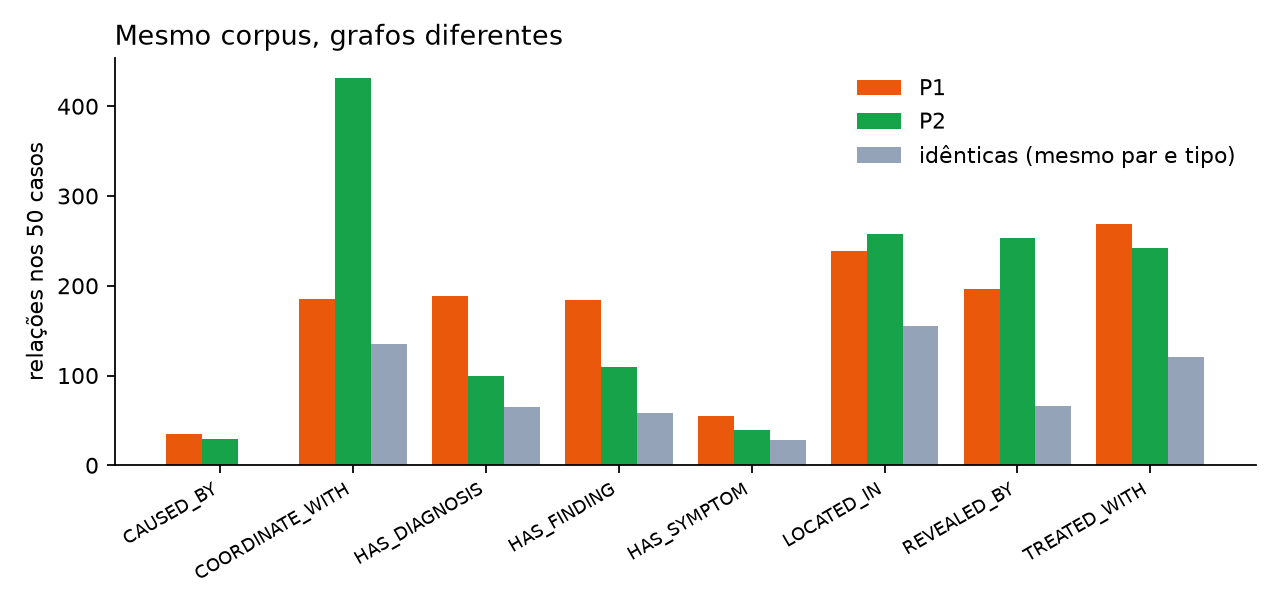

,p1,p2,ambos,so_p1,so_p2,jaccard
relacao,,,,,,
CAUSED_BY,35,29,0,35,29,0.000
COORDINATE_WITH,185,432,135,50,297,0.280
HAS_DIAGNOSIS,189,100,65,124,35,0.290
HAS_FINDING,184,110,58,126,52,0.246
HAS_SYMPTOM,55,39,28,27,11,0.424
LOCATED_IN,239,258,155,84,103,0.453
REVEALED_BY,196,253,66,130,187,0.172
TREATED_WITH,269,242,121,148,121,0.310
TOTAL,1352,1463,628,724,835,0.287


In [22]:
display(Image(filename=str(raiz / "assets/images/relacoes_por_tipo.png"), width=620))
pd.read_csv("data/processed/comparacao_arestas.csv").set_index("relacao")

Só uma fração das relações coincide (mesmo par e tipo), embora os dois métodos usem as mesmas entidades.
O P2 produz muito mais `COORDINATE_WITH` (listas de achados) e menos `HAS_DIAGNOSIS`/`HAS_FINDING`.

In [23]:
ex = pd.read_csv("data/processed/comparacao_exemplos.csv")
print(ex.quem_acerta.value_counts().to_string(), "\n")
for grupo in ["só P2 acerta", "só P1 acerta"]:
    print(f"— {grupo} —")
    sel = ex[(ex.quem_acerta == grupo) & (ex.gold != "NENHUMA")].head(5)
    display(sel[["cabeca", "cauda", "texto_entre", "gold", "p1", "p2"]].reset_index(drop=True))

quem_acerta
só P2 acerta    116
só P1 acerta     48 

— só P2 acerta —


,cabeca,cauda,texto_entre,gold,p1,p2
0,PATIENT,prednisone,the patient was discharged from the hospital after receiving outpatient trea...,TREATED_WITH,NENHUMA,TREATED_WITH
1,myalgia,rash,a mild self-limiting,COORDINATE_WITH,NENHUMA,COORDINATE_WITH
2,rash,diarrhea,episode,COORDINATE_WITH,NENHUMA,COORDINATE_WITH
3,diarrhea,emesis,and occasional,COORDINATE_WITH,NENHUMA,COORDINATE_WITH
4,synovitis,edema,in bilateral metacarpophalangeal joints and grade ii,COORDINATE_WITH,NENHUMA,COORDINATE_WITH


— só P1 acerta —


,cabeca,cauda,texto_entre,gold,p1,p2
0,Water,mouth,dye was given through,LOCATED_IN,LOCATED_IN,NENHUMA
1,patient's condition improved,medications,on anti-tuberculous,TREATED_WITH,TREATED_WITH,NENHUMA
2,Past medical history,atrial fibrillation,revealed,REVEALED_BY,REVEALED_BY,TREATED_WITH
3,enlargement,pancreas,of the,LOCATED_IN,LOCATED_IN,NENHUMA
4,herpes zoster,acyclovir (500 mg,and treated with,TREATED_WITH,TREATED_WITH,CAUSED_BY


## 8. Um achado: a classe rara que o peso de classe estragou

Com 4 exemplos de `CAUSED_BY` contra 409 negativos, o peso de classe rara (positivos × negativos/positivos,
com teto 20) fazia o modelo disparar `CAUSED_BY` em quase qualquer par. A correção é uma regra geral, não um
remendo: **o peso de uma classe nunca passa do número de exemplos positivos que ela tem**
(`limitar_por_suporte`). Contando as arestas `CAUSED_BY` nos 50 casos:

In [24]:
from clinical_kg.learning.pipeline import relacoes_p2, ler_relacoes
from clinical_kg.relations.extract import load_frequencies, DEFAULT_FREQ

freq = load_frequencies(DEFAULT_FREQ)

def arestas_caused_by(modelo):
    total = 0
    for c in casos:
        linhas, _ = relacoes_p2(modelo, c, textos[c["case_id"]], entidades.get(c["case_id"], []), freq)
        total += sum(1 for l in linhas if l["relation"] == "CAUSED_BY")
    return total

sem_limite = ModeloAprendido(limitar_por_suporte=False).ajustar(exemplos, list(textos.values()))
com_limite = ModeloAprendido(limitar_por_suporte=True).ajustar(exemplos, list(textos.values()))
p1_caused = sum(1 for l in ler_relacoes(raiz / "data/processed/relations.csv") if l["relation"] == "CAUSED_BY")
print(f"CAUSED_BY nos 50 casos — P1: {p1_caused} · P2 sem limite: {arestas_caused_by(sem_limite)} · "
      f"P2 com limite: {arestas_caused_by(com_limite)}")

CAUSED_BY nos 50 casos — P1: 35 · P2 sem limite: 105 · P2 com limite: 29


Na validação, `CAUSED_BY` **nunca foi recuperada** em nenhuma configuração testada (pesos máximos de 1 a 20):
com 4 exemplos o modelo não tem evidência. O limite por suporte evita o excesso de arestas, mas não cria
o conhecimento que falta. Também declaramos que o ajuste foi escolhido olhando a mesma validação de 10
casos, o que dá um risco leve de superajuste.

## 9. Caso novo, ao vivo

O visualizador (`streamlit run src/clinical_kg/app/projeto2.py`) mostra os grafos do P1, do P2 e a
comparação, com as arestas coloridas por método. Em *Caso novo (ao vivo)* aceita um texto colado:
passa pelo gazetteer UMLS (entidades) e depois pelos dois métodos. Isso exige o `gazetteer.db`
(ver `data/README.md`); a variável `CLINICAL_KG_GAZETTEER` aponta para ele.

## 10. Limitações e conclusão

* **Poucos dados.** 413 pares em 10 casos; a vantagem do P2 sobre as regras (9 de 10 casos) é robusta,
  mas as diferenças entre variantes do P2 não são distinguíveis.
* **O modelo final viu 10 dos 50 casos no treino.** As relações desses 10 casos são otimistas; nos outros 40
  são previsões reais.
* **O P1 continua em duas etapas.** As entidades (gazetteer UMLS) e o `assertion_status` (negação, hipótese,
  histórico) vêm do P1.
* **Sem LLMs, embeddings nem Transformers**, conforme o enunciado.

**Conclusão.** Um classificador simples sobre n-gramas, PMI/LLR e um modelo de linguagem empilhado supera
as regras do P1 em detecção e, sobretudo, no tipo da relação, de forma consistente entre casos; e produz um
grafo bastante diferente, com muito mais coordenações. O ganho de cada peça isolada não é distinguível
com os dados disponíveis.

## Referências

* Church & Hanks (1990). *Word Association Norms, Mutual Information, and Lexicography.* Computational Linguistics 16(1).
* Dunning (1993). *Accurate Methods for the Statistics of Surprise and Coincidence.* Computational Linguistics 19(1).
* Jurafsky & Martin. *Speech and Language Processing*, 3ª ed. (rascunho). Stanford.
* Wolpert (1992). *Stacked Generalization.* Neural Networks 5(2).
* Nievas Offidani & Delrieux (2024). *Dataset of clinical cases... MultiCaRe.* Data in Brief 52.
* Bodenreider (2004). *The Unified Medical Language System (UMLS).* Nucleic Acids Research 32.